In [54]:
import numpy as np
import matplotlib.pyplot as plt
from pesummary.gw.conversions.spins import opening_angle, component_spins, spin_angles
from pesummary.gw.conversions.angles import _dpsi

In [6]:
def harmonic_amplitudes(
    theta_jn, phase, psi, phi_jl, f_ref, harmonics=[0, 1, 2, 3, 4]
):
    """Calculate the amplitudes of the precessing harmonics as a function of
    orientation

    Parameters
    ----------
    theta_jn: np.ndarray
        the angle between J and line of sight
    phi_jl: np.ndarray
        the precession phase
    f_plus_j: np.ndarray
        The Detector plus response function as defined using the J-aligned frame
    f_cross_j: np.ndarray
        The Detector cross response function as defined using the J-aligned
        frame
    harmonics: list, optional
        The list of harmonics you wish to return. Default is [0, 1]
    """
    theta_jn, phi_jl, tilt_1, tilt_2, phi_12, a_1, a_2 = spin_angles(mass_1, mass_2, inc, spin1x, spin1y, spin1z, spin2x, spin2y, spin2z, f_ref, phase)
    dpsi = _dpsi(theta_jn, phi_jl, beta)
    f_plus_j = np.cos(2 * (psi - dpsi))
    f_cross_j = -1. * np.sin(2 * (psi - dpsi))
    
    amp = {}
    if 0 in harmonics:
        amp[0] = (
            (1 + np.cos(theta_jn)**2) / 2 * f_plus_j
            - 1j * np.cos(theta_jn) * f_cross_j
        )
    if 1 in harmonics:
        amp[1] = 2 * np.exp(-1j * phi_jl) * (
            np.sin(theta_jn) * np.cos(theta_jn) * f_plus_j
            - 1j * np.sin(theta_jn) * f_cross_j
        )
    if 2 in harmonics:
        amp[2] = 3 * np.exp(-2j * phi_jl) * (np.sin(theta_jn)**2) * f_plus_j
    if 3 in harmonics:
        amp[3] = 2 * np.exp(-3j * phi_jl) * (
            -np.sin(theta_jn) * np.cos(theta_jn) * f_plus_j
            - 1j * np.sin(theta_jn) * f_cross_j
        )
    if 4 in harmonics:
        amp[4] = np.exp(-4j * phi_jl) * (
            (1 + np.cos(theta_jn)**2) / 2 * f_plus_j
            + 1j * np.cos(theta_jn) * f_cross_j
        )

    for k in amp.keys():
        amp[k] = np.real(amp[k]*np.exp(2j * phase + 2j * phi_jl))

    return amp

# Vary theta_jn, psi

In [11]:
mass_1 = 30
mass_2 = 20
tilt_1 = np.pi/2
tilt_2 = np.pi/2
phi_12 = np.pi/2
a_1 = 0.5
a_2 = 0.3
f_low = 20
beta = opening_angle(mass_1, mass_2, 0, tilt_1, tilt_2, phi_12, a_1, a_2, f_low, 0)

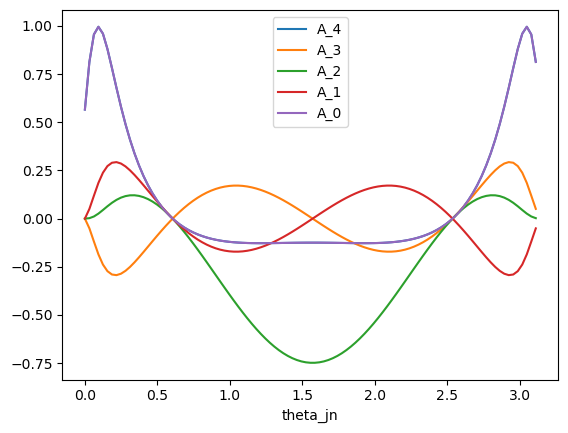

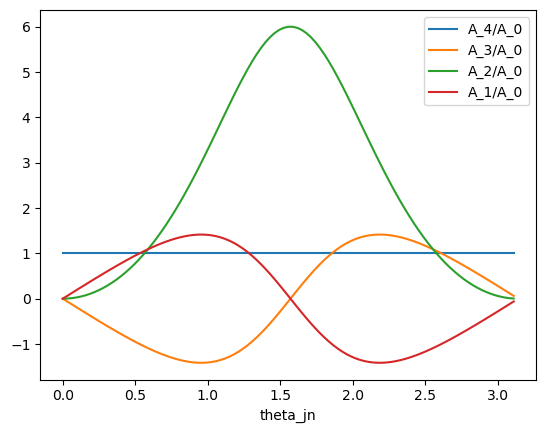

/tmp/ipykernel_1970/4031057504.py:22: RuntimeWarning: divide by zero encountered in divide
  plt.plot(theta_jn, (amps[l]/amps[k]), label=f'A_{l}/A_{k}')
/tmp/ipykernel_1970/4031057504.py:22: RuntimeWarning: invalid value encountered in divide
  plt.plot(theta_jn, (amps[l]/amps[k]), label=f'A_{l}/A_{k}')


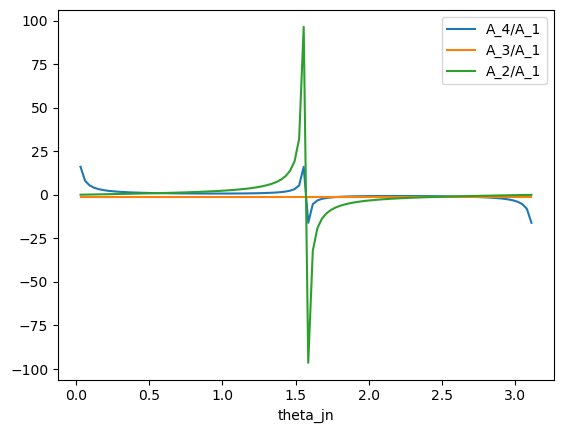

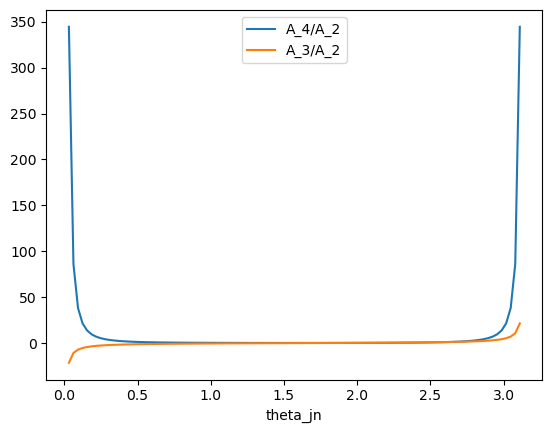

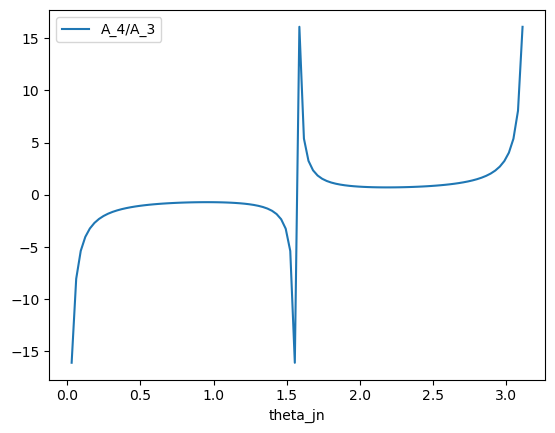

In [50]:
npts = 101
theta_jn = np.linspace(0, np.pi, npts, endpoint=False)
phi_jl = 0 # np.random.rand()*2*np.pi
phase = 0 # np.random.rand()*2*np.pi
psi = np.random.rand()*np.pi/2

amps = {k: [] for k in range(5)}
for i in range(npts):
    _amps = harmonic_amplitudes(theta_jn[i], phi_jl, phase, psi, beta)
    for k in range(5):
        amps[k].append(_amps[k])
amps = {k: np.array(amps[k]) for k in range(5)}

for k in range(4, -1, -1):
    plt.plot(theta_jn, amps[k], label=f'A_{k}')
plt.legend()
plt.xlabel('theta_jn')
plt.show()

for k in range(4):
    for l in range(4, k, -1):
        plt.plot(theta_jn, (amps[l]/amps[k]), label=f'A_{l}/A_{k}')
    plt.legend()
    plt.xlabel('theta_jn')
    plt.show()

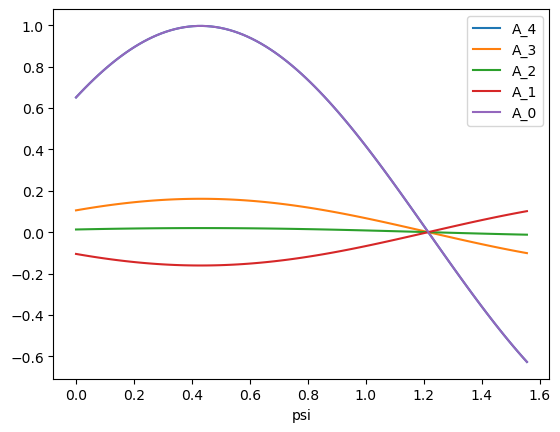

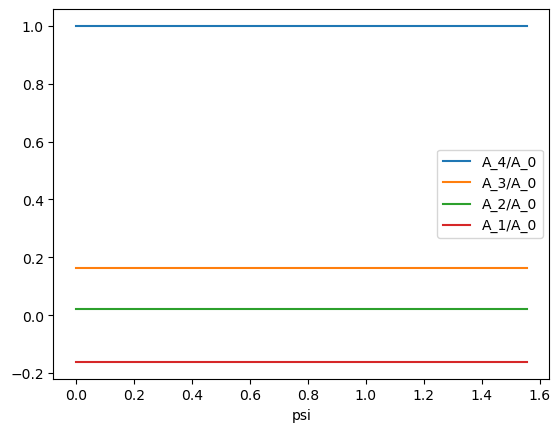

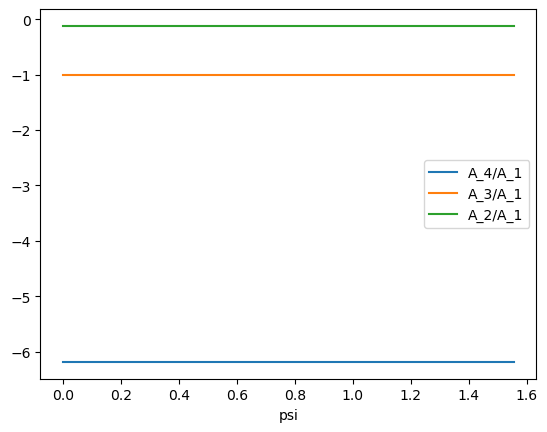

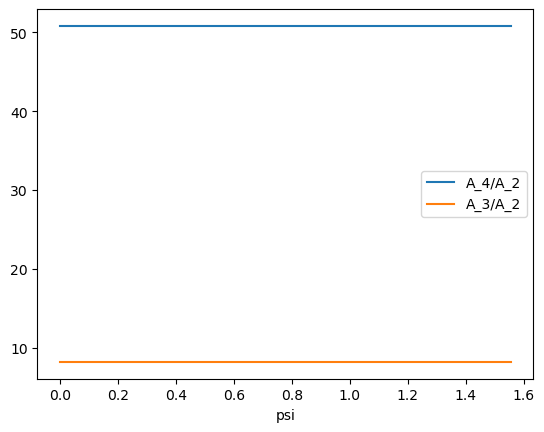

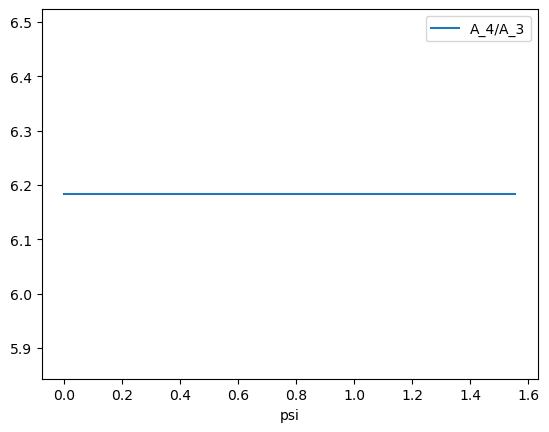

In [52]:
npts = 101
theta_jn = np.random.rand()*np.pi
phi_jl = 0 # np.random.rand()*2*np.pi
phase = 0 # np.random.rand()*2*np.pi
psi = np.linspace(0, np.pi/2, npts, endpoint=False)

amps = {k: [] for k in range(5)}
for i in range(npts):
    _amps = harmonic_amplitudes(theta_jn, phi_jl, phase, psi[i], beta)
    for k in range(5):
        amps[k].append(_amps[k])
amps = {k: np.array(amps[k]) for k in range(5)}

for k in range(4, -1, -1):
    plt.plot(psi, amps[k], label=f'A_{k}')
plt.legend()
plt.xlabel('psi')
plt.show()

for k in range(4):
    for l in range(4, k, -1):
        plt.plot(psi, (amps[l]/amps[k]), label=f'A_{l}/A_{k}')
    plt.legend()
    plt.xlabel('psi')
    plt.show()

At phi_jl = phase = 0, they seperate into three groups: [0,4], [1,3], and [2].

# Vary phi_jl, phase

We must vary phi_jl or phase to further separate the remaining harmonics. We can choose one of these parameters, but not both in order to avoid changing the intrinsic system.

Let's work with a varying phase, and simply calculate phi_jl 'in the background' to keep the same intrinsic system.

In [61]:
theta_jn = 0
phi_jl = 0
phase = 0
psi = 0
tilt_1 = np.pi/2
tilt_2 = np.pi/2
phi_12 = np.pi/2
a_1 = 0.5
a_2 = 0.3
f_ref = 20

iota, spin_1x, spin_1y, spin_1z, spin_2x, spin_2y, spin_2z = component_spins(theta_jn, phi_jl, tilt_1, tilt_2, phi_12, a_1, a_2, mass_1, mass_2, f_ref, phase)

In [62]:
iota, spin_1x, spin_1y, spin_1z, spin_2x, spin_2y, spin_2z

(0.17474158185855818,
 0.12883132528016616,
 0.48311746980062314,
 2.7755575615628914e-17,
 -0.2898704818803739,
 0.07729879516809972,
 2.0816681711721685e-17)

In [73]:
theta_jn = 0
phi_jl = 0
phase = 0
psi = 0
tilt_1 = np.pi/2
tilt_2 = np.pi/2
phi_12 = np.pi/2
a_1 = 0.5
a_2 = 0.3
f_ref = 20

iota, spin_1x, spin_1y, spin_1z, spin_2x, spin_2y, spin_2z = component_spins(theta_jn, phi_jl+0.5/2, tilt_1, tilt_2, phi_12, a_1, a_2, mass_1, mass_2, f_ref, phase+0.5)

In [74]:
iota, spin_1x, spin_1y, spin_1z, spin_2x, spin_2y, spin_2z

(0.17474158185855818,
 0.3446789776593638,
 0.36221043933008873,
 2.7755575615628914e-17,
 -0.21732626359805315,
 0.20680738659561826,
 1.8735013540549515e-17)

In [85]:
mass_1 = 30
mass_2 = 30
iota = 0.1
spin_1x = 0.4
spin_1y = -0.2
spin_1z = 0
spin_2x = -0.1
spin_2y = 0.3
spin_2z = 0
f_ref = 10
phase = 0.5

theta_jn, phi_jl, tilt_1, tilt_2, phi_12, a_1, a_2 = spin_angles(mass_1, mass_2, iota, spin_1x, spin_1y, spin_1z, spin_2x, spin_2y, spin_2z, f_ref, phase)
print(theta_jn, phi_jl, tilt_1, tilt_2, phi_12, a_1, a_2)
theta_jn, phi_jl, tilt_1, tilt_2, phi_12, a_1, a_2 = spin_angles(mass_1, mass_2, iota, spin_1x, spin_1y, spin_1z, spin_2x, spin_2y, spin_2z, f_ref, phase+0.6)
print(theta_jn, phi_jl, tilt_1, tilt_2, phi_12, a_1, a_2)

0.06894763213536774 3.304524798510847 1.5707963267948966 1.5707963267948966 2.356194490192345 0.447213595499958 0.31622776601683794
0.0396290354696302 4.328870966389884 1.5707963267948966 1.5707963267948966 2.356194490192345 0.447213595499958 0.31622776601683794
